# Intraday activity diagnostics

The first 21 ordinary training dates fit the reference. These charts describe the 14 later ordinary dates. Each zero is in the explicit archive calendar. One-minute means distribute each five-minute expectation uniformly.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'config' / 'live_monitoring.v1.json').exists():
    root = root.parent
evidence = root / 'reports' / 'live_monitoring'
figures = evidence / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


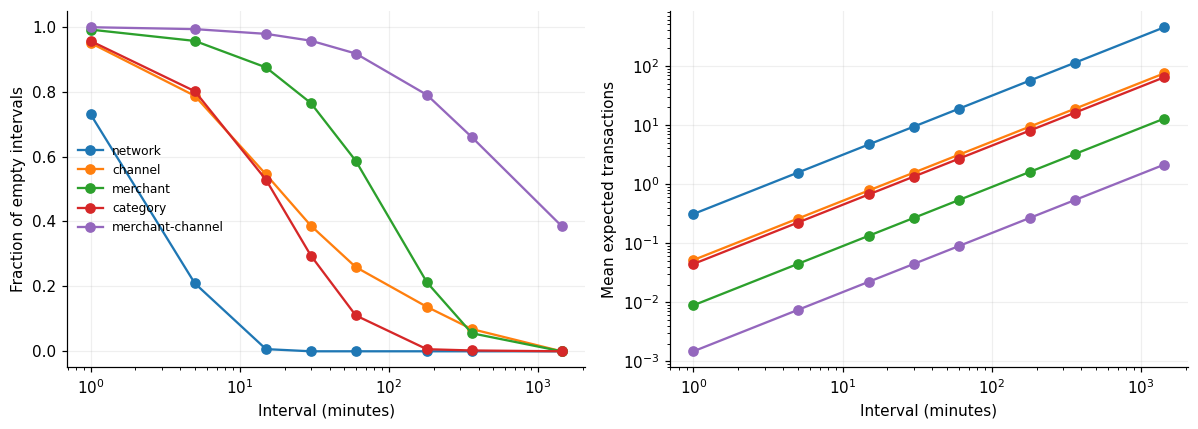

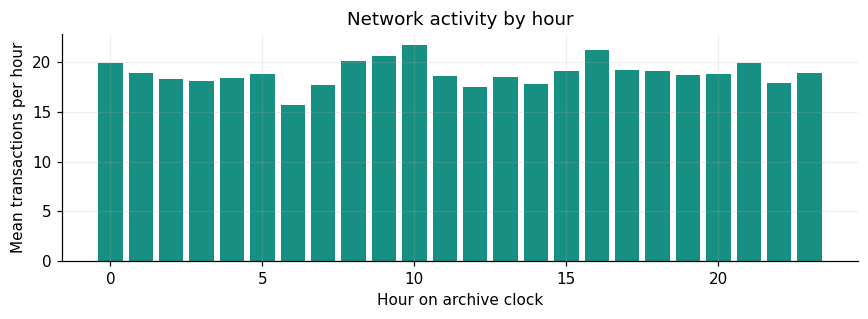

In [2]:
d = pd.read_csv(evidence / 'temporal_diagnostics.csv')
levels = ['network', 'channel', 'merchant', 'category', 'merchant-channel']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for kind in levels:
    means = d[d.scope.eq(kind)].groupby('minutes').mean(numeric_only=True)
    axes[0].plot(means.index, means.empty_fraction, 'o-', label=kind)
    axes[1].plot(means.index, means.mean_expected, 'o-', label=kind)
axes[0].set(ylabel='Fraction of empty intervals', xlabel='Interval (minutes)', xscale='log')
axes[1].set(ylabel='Mean expected transactions', xlabel='Interval (minutes)', xscale='log', yscale='log')
axes[0].legend(frameon=False, fontsize=8)
save(fig, 'exposure_and_empty_intervals')

five = d[(d.minutes == 5) & (d.scope == 'network')].iloc[0]
hourly = np.array(json.loads(five.time_bin_means)).reshape(24, 12).sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(24), hourly, color='#178f82')
ax.set(xlabel='Hour on archive clock', ylabel='Mean transactions per hour', title='Network activity by hour')
save(fig, 'intraday_network_profile')
